# Compute Breadth Score
- Original Tool from **SIBling:** https://aclanthology.org/2024.acl-long.76/
- **Measure:** Each sentence containing the target term is embedded once with XL-LEXEME, the code converts those embeddings into pair-wise cosine distances (1 – cosine_similarity), and it then averages the upper-triangular distances for a given year. That produces a sensible dispersion (or “breadth”) measure for every year reflecting how widely sentences vary in their semantic contexts. 
- **Author:** Naomi Baes

## Load Input Data to Inspect

In [22]:
import os
import pandas as pd

# Set corpus to the folder of files you want to use
df_corpus = pd.read_csv('output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned.csv', sep=',')

# print descriptive information
print("Loaded:", df_corpus_test.shape, "news articles.")
df_corpus_test.head()

Loaded: (121753, 12) news articles.


,id,title,publisher,source_type,pub_province,year,raw_sent,full_article_text,sentence_len,sentence_word_len,article_len,article_word_len
0,306897379,Improving the Lot of the Learning Disabled,WP Company LLC d/b/a The Washington Post,Newspapers,DC,1987,"But at least some of what really is ""going on ...",A couple with a learning-disabled son came to ...,75,65,1552,1245
1,306897379,Improving the Lot of the Learning Disabled,WP Company LLC d/b/a The Washington Post,Newspapers,DC,1987,"Bennett A. Shaywitz and Sally Shaywitz, pediat...",A couple with a learning-disabled son came to ...,41,37,1552,1245
2,389443159,"SCHOOL SWITCHES CAMPUS, NOT APPROACH","Tribune Publishing Company, LLC",Newspapers,IL,1987,"Scott has ADHD, a disability characterized by ...",SCHOOLS WEST BROWARD When he was enrolled a...,25,21,1045,840
3,292639858,Troiani Case Co-Defendant Pleads Guilty to Murder,Los Angeles Times Communications LLC,Newspapers,CA,1987,"That blackout, said Dr. Philip Solomon, was a ...",In a plea bargain that saved him from possible...,37,30,1434,1194
4,292482107,Paying Close Attention to Hyperactive Adults N...,Los Angeles Times Communications LLC,Newspapers,CA,1987,As many as 5% to 10% of all children are hyper...,A man walks down the street He says why a...,23,19,1174,983


In [23]:
#!pip install spacy
#!pip install ipywidgets
#!jupyter nbextension enable --py widgetsnbextension

## Breadth Score

### Randomly sample sentences 

Get random samples of sentences from the input file: randomly sampling X00 sentences from each year (and using as many as possible if the annual sentence count is under this amount)

In [3]:
import pandas as pd

breadth_df = pd.read_csv(
    "output/breadth_scores.csv"
)

annual_counts = (
    breadth_df[
        ["year", "n_total"]
    ]
    .sort_values("year")
    .rename(
        columns={
            "n_total": "available_sentence_embeddings"
        }
    )
)

print(
    annual_counts.to_string(index=False)
)

print(
    "\nMinimum available in any study year:",
    annual_counts[
        "available_sentence_embeddings"
    ].min()
)

 year  available_sentence_embeddings
 1990                            254
 1991                            253
 1992                            358
 1993                            549
 1994                            785
 1995                            986
 1996                           1455
 1997                           1394
 1998                           1837
 1999                           2610
 2000                           3672
 2001                           3170
 2002                           3081
 2003                           3408
 2004                           3617
 2005                           4527
 2006                           5141
 2007                           4910
 2008                           4537
 2009                           4308
 2010                           4171
 2011                           4694
 2012                           4370
 2013                           5203
 2014                           5372
 2015                           4825
 

In [25]:
#!pip install WordTransformer

### Test: Encoding Sentences into Embeddings Using XL-LEXEME (Cassotti et al., 2023)

> This cell loads the XL-LEXEME model (fine-tuned on XLM-R) and encodes **example** sentences into 1024-dimensional embeddings — i.e., numerical vector representations of text learned by the model.

> These vectors capture the **semantic meaning** of the text: sentences that are similar in meaning or usage will be **closer together in vector space** (i.e., have more similar embeddings).

---

> Inside the model: https://huggingface.co/pierluigic/xl-lexeme 
> XL-LEXEME is based on XLM-RoBERTa-large, which has **24 hidden layers**. Each layer applies two key transformations:
>
> 1. **Multi-head self-attention**: The model updates each word’s vector based on how much attention it gives to all other words in the sentence (e.g., “What other words are relevant to this one?”).
> 2. **Feedforward neural network**: Each word vector is passed through a small 2-layer neural net:
>    - Expands to a higher dimension,
>    - Shrinks back to 1024,
>    - Applies non-linear functions (e.g., ReLU).
>
> These operations are repeated **layer by layer**, passing updated vectors through all 24 layers.
> Each layer refines the representation, making it more abstract, contextual, and semantically meaningful.

As a result, the final 1024-dimensional vector for a sentence encodes rich semantic information that can be used for downstream tasks (e.g., similarity, classification, or change detection).

XLM-RoBERTa-large: https://huggingface.co/docs/transformers/en/model_doc/xlm-roberta
- ~355M parameters total (Parameters are the model: internal, learned components that define how the input gets mapped to output. They encode all the learned information that turns raw text into useful representations).
- 24 hidden layers
- 1024 hidden size
- 16 attention heads

In [26]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Load model
model_path = "/home/ec2-user/SageMaker/models/xl-lexeme"  # adjust if needed
model = SentenceTransformer(model_path)

# Test sentences
sentences = [
    "The patient showed signs of ADHD.",
    "She was diagnosed with a mental illness.",
    "The weather is nice today."
]

# Encode
embeddings = model.encode(sentences, batch_size=1)

# Show results
print("Vector shape:", np.array(embeddings).shape)  # should be (3, embedding_dim)
print("\nVector preview (first sentence):\n", embeddings[0][:10])  # first 10 dims (there are 1024-dimensions in the vector in total)


Vector shape: (3, 1024)

Vector preview (first sentence):
 [-0.30480647 -0.72317624 -0.4994053  -0.8155162  -0.0104328   0.5959236
  0.96045715  1.1632907   0.85524046 -0.45481366]


### Encoding Sentences into Embeddings Using XL-LEXEME

#### What this script below does  
Batch-encode every `.txt` file in **`./output/breadth_samples`** with the **XL-LEXEME** model and save the per-sentence embeddings. You can increase batch size depending on memoy. (GPU executes the model; nvidia-smi gives a dashboard for documentation)

| Stage | Details |
|-------|---------|
| **Config** | Define input/output paths, model path, GPU limits, batch size (1), max 512 tokens, and turn off HF tokenizer parallelism. |
| **`encode_file(fname)`** | • Ignore non-text files.<br>• Derive **target word** from filename.<br>• Read sentences, keep only those containing the target.<br>• For each kept sentence:<br>&nbsp;&nbsp;– Locate target token index.<br>&nbsp;&nbsp;– Center a ≤512-token window around it.<br>&nbsp;&nbsp;– Wrap into `InputExample` (text + start/end span).<br>• Load XL-LEXEME once per worker and encode all examples.<br>• Write float32 embeddings to `<file>_XLL.txt` next to the source file.<br>• Return success / skip / error flag. |
| **Parallel runner** | Use `ProcessPoolExecutor` (context =`spawn` on Windows, `fork` on *nix). `N_WORKERS` is currently **1** → single-GPU safe. |
| **Progress & logging** | Show `tqdm` progress bar, runtime per file. Log skipped/error files and reasons to `skipped_files.log`. |

**Output:** For every input file containing the target word you get a companion `_XLL.txt` matrix (rows = sentences, cols = 1024-d XL-LEXEME embeddings) ready for cosine-similarity, clustering, etc.

#### Note:  ---------------------------------------------
##### Target-aware encoding  
* Filename chunk **before the first “_”** is treated as the *target word* (e.g. `schizophrenia` in `schizophrenia_raw-sentence_1971.txt`).  
* Only sentences containing that word are kept.  
* Each sentence is wrapped as an `InputExample`  

  ```python
  InputExample(
      texts=" ".join(tokens_trunc),
      positions=[target_idx, target_idx + 1]   # span of the target
  )
  ```  
→ XL-LEXEME returns the hidden state at that span, giving a lexeme-level embedding.
Handling the transformer length cap

    MAX_TOKENS (here 384) is the per-sequence limit.

For sentences longer than that, keep a window centred on the target:
half  = MAX_TOKENS // 2
start = max(0, tgt_idx - half)
end   = min(len(tokens), start + MAX_TOKENS)
start = max(0, end - MAX_TOKENS)  # re-centre if near sentence end

**Why this matters	  | Effect on downstream analysis**
- Target span → vector  | Produces token-level embeddings for cosine/APD lexical-change metrics. 
- Fixed window size	  | Ensures efficient, reproducible batching.
- Bidirectional attention	| Target attends to every token in the window, capturing rich context.

In [1]:
#!python 2_step1_encode_sentences_1-year_lexeme_gpu-parallel.py #~8 min total with GPU (several hours with CPU)

# Note: Re-ran on sentences_all folder for the final analyses

### What this script do? 

1. **Scans one output folder** for every file that ends in **`_XLL.txt`**.  
   *These are the XL-LEXEME sentence-vector files you just created.*

2. **Parses each file name** to capture two key bits of metadata:
   * **`term`** &nbsp;→&nbsp; the target word (e.g. `schizophrenia`)  
   * **`year`** &nbsp;→&nbsp; the publication year (e.g. `1983`)

3. **Loads the sentence vectors** stored in that file  
   *(each sentence is a 1024-dimensional XL-LEXEME embedding).*

4. **Computes pair-wise cosine-dissimilarity (i.e., cosine distance)** between all unique (only one side of similarity matrix) sentence pairs inside the file  
   \[
   \text{dissimilarity} = 1 - \cos(\theta)
   \]
   
   **A. compute the full cosine-similarity matrix** (sims = cosine_similarity(mat)
   
   **B. Convert to cosine-distance and rescale into [0,1]** (dis = 1.0 - sims)/ 2.0
   
   **C. Mask off the diagonal & lower traingle to give you the unique pairwise distances**

   

5. **Summarises those distances** with three statistics:

   | metric | meaning |
   |--------|---------|
   | **mean** | average dissimilarity between all unique sentence pairs |
   | **sd**   | spread of those values (standard deviation) |
   | **se**   | uncertainty around the mean (standard error) |

6. **Repeats** for every file and **writes one tidy CSV** containing  



In [2]:
%run 2_step2_compute_breadth-score.py \
    --dir output/embeddings/sentences_all \
    --csv output/breadth_scores.csv \
    --term_name ADHD \
    --start_year 1990 \
    --end_year 2025 \
    --n_per_year 50 \
    --n_reps 10 \
    --n_ci_reps 500 \
    --ci 0.95 \
    --seed 42

Wrote 36 rows -> output/breadth_scores.csv


   year  breadth_score  breadth_rep_se  ci_lower  ci_upper  n_total
0  1990       0.205192        0.004638  0.194701  0.215684      254
1  1991       0.194933        0.005037  0.183538  0.206328      253
2  1992       0.205951        0.002719  0.199799  0.212102      358
3  1993       0.193472        0.005900  0.180124  0.206819      549
4  1994       0.204760        0.005181  0.193041  0.216480      785


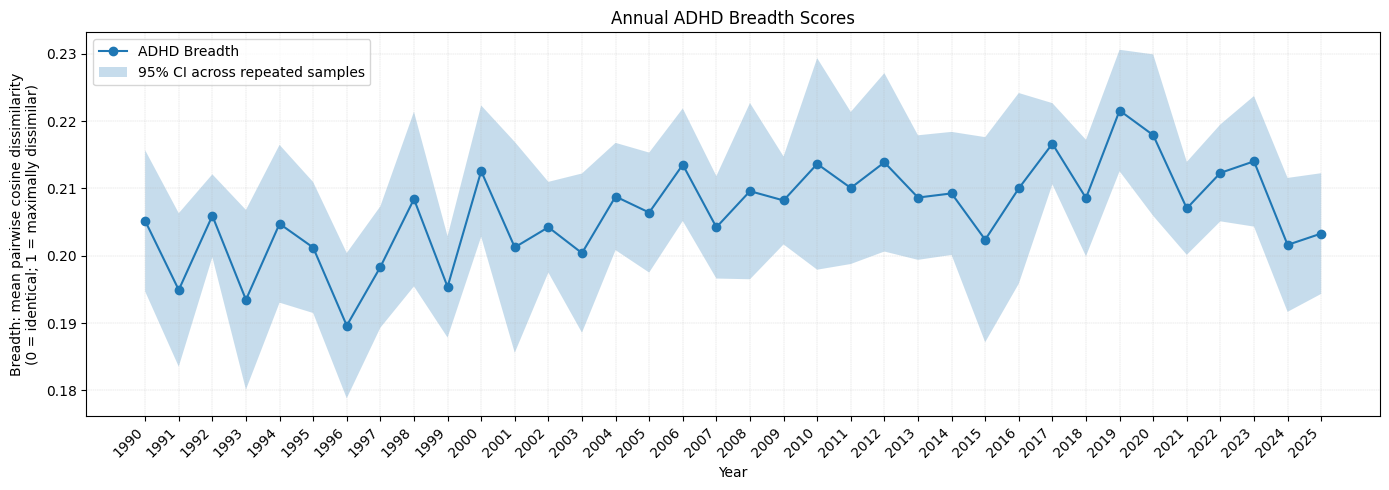

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t


# =========================================================
# Read and prepare data
# =========================================================

df = pd.read_csv(
    "output/breadth_scores.csv"
)

plot_df = (
    df.loc[
        (df["term"].str.lower() == "adhd")
        & df["year"].between(1990, 2025)
    ]
    .sort_values("year")
    .copy()
)

# 95% t interval based on the 10 repeated estimates
t_critical = t.ppf(
    0.975,
    df=plot_df["n_reps"].iloc[0] - 1
)

plot_df["ci_lower"] = (
    plot_df["breadth_score"]
    - t_critical * plot_df["breadth_rep_se"]
)

plot_df["ci_upper"] = (
    plot_df["breadth_score"]
    + t_critical * plot_df["breadth_rep_se"]
)

print(
    plot_df[
        [
            "year",
            "breadth_score",
            "breadth_rep_se",
            "ci_lower",
            "ci_upper",
            "n_total",
        ]
    ].head()
)


# =========================================================
# Plot
# =========================================================

years = plot_df["year"].to_numpy()
breadth = plot_df["breadth_score"].to_numpy()
ci_lower = plot_df["ci_lower"].to_numpy()
ci_upper = plot_df["ci_upper"].to_numpy()

plt.figure(figsize=(14, 5))

plt.plot(
    years,
    breadth,
    marker="o",
    label="ADHD Breadth",
)

plt.fill_between(
    years,
    ci_lower,
    ci_upper,
    alpha=0.25,
    label="95% CI across repeated samples",
)

plt.xticks(
    years,
    rotation=45,
    ha="right",
)

plt.xlabel("Year")

plt.ylabel(
    "Breadth: mean pairwise cosine dissimilarity\n"
    "(0 = identical; 1 = maximally dissimilar)"
)

plt.title(
    "Annual ADHD Breadth Scores"
)

plt.grid(
    True,
    linewidth=0.3,
    linestyle="--",
    alpha=0.6,
)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ░░  OLS line-fit (+95 % CI) *and* key statistics  ░░
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import linregress, t

# 1 ─── load & pre-filter  ──────────────────────────────────────────
df  = (pd.read_csv("output/breadth_scores.csv")
         .astype({"year": int})
         .loc[lambda d: d["year"] >= 1980])

terms_to_plot = ["adhd"]       # or several

for term in terms_to_plot:
    sub  = df.query("term == @term").sort_values("year")
    x    = sub["year"].values
    y    = sub["cosine_dissim_mean"].values
    se_y = sub["cosine_dissim_se"].values          # ± 1 SE for dots

    # 2 ─── OLS fit ────────────────────────────────────────────────
    slope, intercept, r, p, stderr = linregress(x, y)
    y_hat = intercept + slope * x

    resid  = y - y_hat
    mse    = np.sum(resid**2) / (len(x) - 2)
    x̄     = x.mean()
    sxx    = np.sum((x - x̄)**2)
    t_crit = t.ppf(0.975, df=len(x)-2)            # 95 % two-sided
    se_line = np.sqrt(mse * (1/len(x) + (x - x̄)**2 / sxx))
    ci_half = t_crit * se_line

    # 3 ─── plot ──────────────────────────────────────────────────
    plt.figure(figsize=(14, 5))
    plt.fill_between(x, y - se_y, y + se_y, color="lightgrey", alpha=.0,
                     label="± 1 SE  (means)")
    plt.scatter(x, y, color="black", s=28, alpha=.6, label="Yearly mean")

    plt.plot(x, y_hat, color="royalblue", lw=2,
             label=f"OLS fit: slope ={slope:.4f}")
    plt.fill_between(x, y_hat - ci_half, y_hat + ci_half,
                     color="royalblue", alpha=.2, label="95 % CI (fit)")

    # 4 ─── cosmetics & ticks  ────────────────────────────────────
    tick_every = 1
    ticks       = x[::tick_every]
    tick_labels = ticks.astype(str)
    plt.xticks(ticks, tick_labels, rotation=45, ha="right")

    plt.xlabel("Year")
    plt.ylabel("Cosine distance (0 = identical to 1 = opposite)")
    plt.title(f"Annual semantic dispersion for “{term}” (1980-{x.max()})")
    plt.grid(True, lw=.8, ls="--", alpha=.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 5 ─── stats read-out  ───────────────────────────────────────
    r2   = r**2
    print(f"── {term} — OLS summary ──────────────────────────────")
    print(f"n (years)      : {len(x)}")
    print(f"Slope          : {slope:.4f}  (± {stderr:.4f})")
    print(f"Intercept      : {intercept:.4f}")
    print(f"R-squared      : {r2:.4f}")
    print(f"Pearson r      : {r:.4f}")
    print(f"p-value (slope): {p:.4g}")
    print("────────────────────────────────────────────────────\n")


### STATS: Linear Regression Model - Fitting the Outcome Variable as a Function of Year

Time series analysis for psychological research: examining and forecasting change: https://doi.org/10.3389/fpsyg.2015.00727

In [ ]:
# reinstall SciPy ≥1.10,<2.0 so _lazywhere is present
#!pip install "scipy==1.11.4" --no-cache-dir -q
# or, with conda:
# !conda install -y -c conda-forge "scipy>=1.10,<2.0"

In [ ]:
%run 2_step3_fit_linear_model_breadth-score.py # try a more xcomplex step by step procedure as residuals are often autocorrelated in time series data making OLS unreliable

**Method:** To identify the most appropriate time-series model, we first examined whether the raw dispersion series was stationary. An Augmented Dickey–Fuller test failed to reject a unit root, so the data were differenced once. We then fit a small grid of candidate ARIMA models—autoregressive orders 0-2 crossed with moving-average orders 0-1, each estimated with a drift term when permissible—and compared them with the Akaike Information Criterion. The ARIMA(2, 1, 1) specification produced the lowest AIC by more than four points, satisfying the usual “strong evidence” threshold for model preference. Finally, Ljung–Box tests at lags 6 and 12 confirmed that this model’s residuals approximated white noise, validating it as the best-fitting and most parsimonious representation of the data.

**Interpreation**:  The best‐fitting ARIMA(2,1,1) specification for adhd’s annual dispersion series implies that, after first differencing, there is no enduring trend—dispersion behaves like a zero‐mean random walk rather than steadily increasing or decreasing. The two AR terms and single MA term capture short‐lived shocks: any unusually high or low dispersion in one year tends to “mean‐revert” within one to two years, rather than accumulating over time. Moreover, the absence of a drift term confirms that there is no systematic bias upward or downward in semantic spread. Ljung–Box tests on the residuals indicate no remaining autocorrelation, meaning the ARIMA model has effectively absorbed all predictable temporal structure. In practical terms, what looks like a rising trend under simple OLS regression is in fact the by‐product of clustered fluctuations—once these are accounted for, there is no sustained semantic broadening or narrowing across the period.

VALIDATION: Cosine *distance* on a 0 – 1 scale
----------------------------------

We map cosine similarity ( −1 → +1 scale) to a friendlier 0 – 1 scale distance with

$$
d_{0\text{–}1} = \frac{1-\cos(\theta)}{2}
$$

* \(d = 0\)   identical / paraphrase  
* \(d \approx 0.50\)   orthogonal (cos ≈ 0)  
* \(d = 1.00\)   theoretical opposite (cos = −1, rare with embeddings)

---

### From a single pair to the full *n × n* matrix  

For a batch of *n* sentences we

1. **Encode** each sentence → 1024-d XL-LEXEME vector  = *sentence-vector matrix: 500 x 1024*
2. **Measure similarity**                              = *cosine similarity matrix = 500 x 500* (+1 -> -1 scale)

   \[
     S_{ij}\;=\;\cos\!\bigl(\vec v_i,\vec v_j\bigr)\quad\in[-1,\;1]
   \]

3. **Convert to distance** (*0 – 2/2) = (0-1* scale)

   \[
     D_{ij}\;=\;d_{0\text{–}1}\;=\;\frac{1-\cos\!\bigl(\vec v_i,\vec v_j\bigr)}{2}
   \]

The result is an *n × n* **symmetric distance matrix** = *cosine distance matrix = 500 x 500* (0 -> 1 scale)

\[
\mathbf D \;=\;
\begin{bmatrix}
 0 & d_{01} & \dots & d_{0,n-1}\\
 d_{10} & 0 & \dots & d_{1,n-1}\\
 \vdots & \vdots & \ddots & \vdots\\
 d_{n-1,0} & d_{n-1,1} & \dots & 0
\end{bmatrix}
\]

* Because \(D_{ij}=D_{ji}\) and the diagonal is zero, we usually **store only the upper-triangular part**  
  (½ · *n* · (*n* − 1) numbers) to save space and avoid redundancy.

---

Note: Dividing by 2 is a **linear rescaling** – it does not change any relative rankings or downstream statistics, it merely makes the range easier to interpret (0 = identical, 1 = opposite).



In [7]:
# Validation cell ─ does the 0-1 cosine-distance behave as “similar vs. different”?
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np, textwrap, pprint

model = SentenceTransformer("/home/ec2-user/SageMaker/models/xl-lexeme")

################## YOU CAN CHANGE THESE SENTENCES #################
s1 = "The patient showed signs of adhd."
s2 = "Doctors observed symptoms of adhd in the patient."
s3 = "The weather is nice today."
sentences = [s1, s2, s3]

# ---- encode & convert similarity (−1‥+1) → distance (0‥1)
vecs = model.encode(sentences, normalize_embeddings=True)
dist_01 = (1.0 - cosine_similarity(vecs)) / 2.0        # 0 = identical … 1 = opposite

# helper for pretty print
def p(lbl, d): print(f"{lbl:<30}:  distance = {d:0.3f}")

print("\nCosine-distance results (scale 0 = identical … 1 = very different)\n")
p("Sentence 1  vs Sentence 2  (should be *close*)", dist_01[0,1])
p("Sentence 1  vs Sentence 3  (should be *far*)",   dist_01[0,2])
p("Sentence 2  vs Sentence 3  (should be *far*)",   dist_01[1,2])

# intuitive pass / fail
okay_close = dist_01[0,1] < 0.30
okay_far   = (dist_01[0,2] > 0.70) and (dist_01[1,2] > 0.70)

print("\nInterpretation:")
print(f"✓ ‘close’ pair < 0.30  → {'PASS' if okay_close else 'FAIL'}")
print(f"✓ ‘far’   pairs > 0.70 → {'PASS' if okay_far   else 'FAIL'}")

print("\nSentences used in this quick test:")
wrap = textwrap.TextWrapper(width=72, subsequent_indent=" " * 6)
for i, s in enumerate(sentences, 1):
    print(f" {i}: {wrap.fill(s)}")


ModuleNotFoundError: No module named 'sentence_transformers'

# End of Script